# NDVI K2 phenology at field plots — exploratory notebook

Samples **only plot locations** from annual intercept–amplitude–phase GeoTIFFs; does not write rasters or classification products. Derives peak DOY, maximum green-up rate, season length and rise–fall asymmetry from independently fitted **NDVI** K2 curves. Includes diagnostic plots. **Do not interpret timing until verifying phase encoding** against the original Earth Engine harmonic definition or observed curve.

In [5]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer
from IPython.display import display

HARMONIC_ROOT = Path(r"A:\NCA_DATA\S2_Harmonics")
POINTS_CSV = Path(r"A:\NCA_DATA\Validation\Supervised_State_Classification\FieldVeg_K2_IA45_Training.csv")
YEARS = list(range(2016, 2026))
# Field table must contain plot coordinates; update names below after inspecting printed columns.
PLOT_ID_COL = 'PlotID'
YEAR_COL = 'Year'
X_COL = "Easting"
Y_COL = "Northing"
POINT_CRS = "EPSG:26911"
# IMPORTANT: inspect the TIFF band names and confirm how phase was calculated.
# For y = c + A cos(wt - phi), choose 'cos_minus'.
# For y = c + A cos(wt + phi), choose 'cos_plus'.
# For y = c + A sin(wt + phi), choose 'sin_plus'.
PHASE_CONVENTION = 'cos_minus'
PHASE_UNITS = 'radians'  # or 'degrees'
TIME_ORIGIN_DOY = 1  # must agree with export's Fourier time origin
SEASON_THRESHOLD = 0.5 # halfway between annual minimum and principal peak
PEAK_AMBIGUITY_FRACTION = 0.1 # local secondary peak within 10% of range of primary
MIN_RANGE = 0.025 # NDVI units; diagnostic, not a validated ecological threshold
DOY = np.arange(1, 366)


In [6]:
points = pd.read_csv(POINTS_CSV, low_memory=False)
print('Columns:', list(points.columns))
required = [PLOT_ID_COL, YEAR_COL, X_COL, Y_COL]
missing = [c for c in required if c not in points.columns]
if missing:
    raise KeyError(f'Missing plot columns {missing}. Set X_COL, Y_COL, POINT_CRS above based on printed columns.')
points = points.dropna(subset=required).copy()
points[YEAR_COL] = pd.to_numeric(points[YEAR_COL], errors='coerce')
points = points[points[YEAR_COL].isin(YEARS)].copy()
points = points.drop_duplicates(subset=[PLOT_ID_COL, YEAR_COL])
print('Plot-years:', len(points)); display(points[required].head())


Columns: ['PlotID', 'Year', 'Easting', 'Northing', 'parent_cluster', 'parent_label', 'max_membership', 'second_membership', 'membership_margin', 'membership_1', 'membership_2', 'membership_3', 'membership_4', 'membership_5', 'membership_6', 'membership_7', 'membership_8', 'raw_subcluster', 'state_id', 'state_label', 'state_type', 'is_reference', 'nobs', 'constant_B2', 'constant_B3', 'constant_B4', 'constant_B5', 'constant_B6', 'constant_B7', 'constant_B8', 'constant_B8A', 'constant_B11', 'constant_B12', 'constant_NDVI', 'constant_NDMI', 'constant_NDRE', 'constant_BSI', 'constant_NBR2', 'amp1_B2', 'amp1_B3', 'amp1_B4', 'amp1_B5', 'amp1_B6', 'amp1_B7', 'amp1_B8', 'amp1_B8A', 'amp1_B11', 'amp1_B12', 'amp1_NDVI', 'amp1_NDMI', 'amp1_NDRE', 'amp1_BSI', 'amp1_NBR2', 'amp2_B2', 'amp2_B3', 'amp2_B4', 'amp2_B5', 'amp2_B6', 'amp2_B7', 'amp2_B8', 'amp2_B8A', 'amp2_B11', 'amp2_B12', 'amp2_NDVI', 'amp2_NDMI', 'amp2_NDRE', 'amp2_BSI', 'amp2_NBR2']
Plot-years: 479


,PlotID,Year,Easting,Northing
0,100,2016,589959.8600,4.767951e+06
1,101,2016,590024.1050,4.767835e+06
2,102,2016,593417.5396,4.768936e+06
3,103,2016,593400.7996,4.768939e+06
4,104,2016,594390.5446,4.768703e+06


In [7]:
def annual_path(year):
    return HARMONIC_ROOT / str(year) / f'{year}_K2_InterceptAmpPhase_nobs_RMSE.tif'

def band_names(src):
    return [str(x or f'band_{i}').strip() for i, x in enumerate(src.descriptions, 1)]

for yr in YEARS:
    path = annual_path(yr)
    if path.exists():
        with rasterio.open(path) as ds:
            print('Example TIFF:', path, '| CRS:', ds.crs)
            print('NDVI-related bands:', [(i, s) for i,s in enumerate(band_names(ds),1) if 'ndvi' in s.lower()])
        break
else:
    raise FileNotFoundError('No annual K2 TIFF found; verify HARMONIC_ROOT.')


Example TIFF: A:\NCA_DATA\S2_Harmonics\2016\2016_K2_InterceptAmpPhase_nobs_RMSE.tif | CRS: PROJCS["NAD83 / UTM zone 11N",GEOGCS["NAD83",DATUM["North American Datum 1983",SPHEROID["GRS 1980",6378137,298.257222101004]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
NDVI-related bands: [(11, 'constant_NDVI'), (26, 'amp1_NDVI'), (41, 'phase1_NDVI'), (56, 'amp2_NDVI'), (71, 'phase2_NDVI'), (87, 'RMSE_NDVI')]


In [8]:
def resolve_ndvi_bands(src):
    # Requires explicit NDVI intercept, amplitude 1/2 and phase 1/2.
    # Prevents silently using phase from a different index/order.
    names = band_names(src)
    groups = {
        'beta0': [r'^(constant|intercept|beta0)[_-]ndvi$', r'^ndvi[_-](constant|intercept|beta0)$'],
        'a1': [r'^(amp1|amplitude1|amp_1)[_-]ndvi$', r'^ndvi[_-](amp1|amplitude1|amp_1)$'],
        'a2': [r'^(amp2|amplitude2|amp_2)[_-]ndvi$', r'^ndvi[_-](amp2|amplitude2|amp_2)$'],
        'p1': [r'^(phase1|phase_1|phi1|phi_1)[_-]ndvi$', r'^ndvi[_-](phase1|phase_1|phi1|phi_1)$'],
        'p2': [r'^(phase2|phase_2|phi2|phi_2)[_-]ndvi$', r'^ndvi[_-](phase2|phase_2|phi2|phi_2)$'],
    }
    idx = {}
    for key, patterns in groups.items():
        match = [i for i,name in enumerate(names, 1) if any(re.fullmatch(pt,name.lower()) for pt in patterns)]
        if len(match) != 1:
            raise ValueError(f'{key}: expected one NDVI band, got {match}. Available NDVI bands: '
                             +repr([(i,s) for i,s in enumerate(names,1) if 'ndvi' in s.lower()]))
        idx[key] = match[0]
    return idx

def sample_year(df, year):
    path=annual_path(year)
    if not path.exists():
        print(f'Skipping {year}: no raster')
        return pd.DataFrame()
    with rasterio.open(path) as ds:
        ix=resolve_ndvi_bands(ds)
        xy=df[[X_COL,Y_COL]].apply(pd.to_numeric,errors='coerce').to_numpy(float)
        if not np.isfinite(xy).all():
            raise ValueError(f'Invalid plot coordinates for {year}')
        if str(ds.crs) != str(POINT_CRS):
            t=Transformer.from_crs(POINT_CRS,ds.crs,always_xy=True)
            xy=np.array([t.transform(x,y) for x,y in xy])
        coords=list(map(tuple,xy))
        # Only 5 bands at selected points; never reads complete raster.
        vals=np.asarray(list(ds.sample(coords,indexes=list(ix.values()),masked=True)))
        values=np.ma.filled(vals.astype(float),np.nan)
        result=df[[PLOT_ID_COL,YEAR_COL]].copy().reset_index(drop=True)
        for j,key in enumerate(ix): result[key]=values[:,j]
        result['in_bounds']=[ds.bounds.left<=x<=ds.bounds.right and ds.bounds.bottom<=y<=ds.bounds.top for x,y in coords]
        result.loc[~result['in_bounds'],list(ix)] = np.nan
        return result

frames=[]
for year in YEARS:
    sub=points[points[YEAR_COL].eq(year)]
    if len(sub):
        sampled=sample_year(sub,year)
        if len(sampled): frames.append(sampled)
if not frames: raise RuntimeError('No plot-year samples available.')
sampled=pd.concat(frames,ignore_index=True)
valid=np.isfinite(sampled[['beta0','a1','a2','p1','p2']]).all(axis=1)
print(f'Complete phase/amp fits: {valid.sum()} / {len(sampled)}')
display(sampled.head())


Complete phase/amp fits: 479 / 479


,PlotID,Year,beta0,a1,a2,p1,p2,in_bounds
0,100,2016,0.126941,0.079495,0.031102,1.320598,2.965630,True
1,101,2016,0.155435,0.106519,0.026460,0.934430,2.119081,True
2,102,2016,0.140608,0.036501,0.010803,1.133071,-2.332327,True
3,103,2016,0.138169,0.036057,0.011567,1.160019,-2.061493,True
4,104,2016,0.151693,0.063852,0.022509,1.322101,2.877918,True


In [9]:
def reconstruct_ndvi(rec, doy=DOY):
    t=np.asarray(doy,dtype=float) - TIME_ORIGIN_DOY
    theta=2*np.pi*t/365.0
    p1,p2=float(rec['p1']),float(rec['p2'])
    if PHASE_UNITS == 'degrees': p1,p2=np.deg2rad([p1,p2])
    if PHASE_CONVENTION == 'cos_minus':
        v=rec['beta0']+rec['a1']*np.cos(theta-p1)+rec['a2']*np.cos(2*theta-p2)
    elif PHASE_CONVENTION == 'cos_plus':
        v=rec['beta0']+rec['a1']*np.cos(theta+p1)+rec['a2']*np.cos(2*theta+p2)
    elif PHASE_CONVENTION == 'sin_plus':
        v=rec['beta0']+rec['a1']*np.sin(theta+p1)+rec['a2']*np.sin(2*theta+p2)
    else: raise ValueError('Unknown PHASE_CONVENTION')
    return np.asarray(v,dtype=float)

def phenology_metrics(rec):
    v=reconstruct_ndvi(rec)
    # Periodic derivatives; wrap January/December instead of creating edge artifacts.
    rate=(np.roll(v,-1)-np.roll(v,1))/2.0
    peak=int(np.argmax(v)); trough=int(np.argmin(v))
    rng=float(v.max()-v.min())
    threshold=float(v.min()+SEASON_THRESHOLD*rng)
    # Crossing before and after global peak: cyclic search, can span Jan 1.
    above=v>=threshold
    rise=None; fall=None
    for step in range(1,366):
        j=(peak-step)%365
        if not above[j]: rise=(j+1)%365; break
    for step in range(1,366):
        j=(peak+step)%365
        if not above[j]: fall=j; break
    rising = (peak-rise)%365 if rise is not None else np.nan
    falling = (fall-peak)%365 if fall is not None else np.nan
    duration = rising+falling if np.isfinite(rising) and np.isfinite(falling) else np.nan
    asym=(falling-rising)/duration if duration>0 else np.nan
    localmax=np.where((v>=np.roll(v,1))&(v>np.roll(v,-1)))[0]
    other=[i for i in localmax if min((i-peak)%365,(peak-i)%365)>20]
    second=max([v[i] for i in other],default=np.nan)
    ambiguous=(np.isfinite(second) and (v[peak]-second)<PEAK_AMBIGUITY_FRACTION*rng)
    return pd.Series({'peak_ndvi_doy':peak+1,'peak_ndvi_fit':v[peak],
                      'ndvi_range_fit':rng,'max_greenup_rate':rate.max(),
                      'max_senescence_rate':rate.min(),
                      'greenup_doy':rise+1 if rise is not None else np.nan,
                      'senescence_doy':fall+1 if fall is not None else np.nan,
                      'season_length_days':duration,'rise_fall_asymmetry':asym,
                      'two_peak_ambiguous':bool(ambiguous),
                      'weak_seasonality':rng<MIN_RANGE})

valid_sample=sampled.loc[valid].copy().reset_index(drop=True)
metrics=valid_sample.apply(phenology_metrics,axis=1)
plot_features=pd.concat([valid_sample,metrics],axis=1)
print('Derived metrics:',len(plot_features))
display(plot_features.head())
display(plot_features.groupby(YEAR_COL)[['peak_ndvi_doy','max_greenup_rate','season_length_days','rise_fall_asymmetry']].agg(['count','median']))
print('Ambiguous peaks:',plot_features.two_peak_ambiguous.mean().round(3),'| Weak seasonality:',plot_features.weak_seasonality.mean().round(3))


Derived metrics: 479


,PlotID,Year,beta0,a1,a2,p1,p2,in_bounds,peak_ndvi_doy,peak_ndvi_fit,ndvi_range_fit,max_greenup_rate,max_senescence_rate,greenup_doy,senescence_doy,season_length_days,rise_fall_asymmetry,two_peak_ambiguous,weak_seasonality
0,100,2016,0.126941,0.079495,0.031102,1.320598,2.965630,True,83,0.236894,0.176118,0.001990,-0.002241,20,144,124,-0.016129,False,False
1,101,2016,0.155435,0.106519,0.026460,0.934430,2.119081,True,59,0.287999,0.217710,0.002254,-0.002483,355,126,136,-0.014706,False,False
2,102,2016,0.140608,0.036501,0.010803,1.133071,-2.332327,True,92,0.181121,0.082695,0.000537,-0.000999,333,161,193,-0.284974,False,False
3,103,2016,0.138169,0.036057,0.011567,1.160019,-2.061493,True,98,0.176993,0.082618,0.000611,-0.001013,322,166,209,-0.349282,False,False
4,104,2016,0.151693,0.063852,0.022509,1.322101,2.877918,True,82,0.237798,0.136482,0.001554,-0.001696,18,144,126,-0.015873,False,False


peak_ndvi_doy        max_greenup_rate           season_length_days  \
             count median            count    median              count   
Year                                                                      
2016           255   74.0              255  0.001517                255   
2018           106   74.0              106  0.002556                106   
2025           118  117.5              118  0.001492                118   

            rise_fall_asymmetry            
     median               count    median  
Year                                       
2016  136.0                 255 -0.031746  
2018  120.0                 106 -0.008621  
2025  125.0                 118 -0.049672

Ambiguous peaks: 0.048 | Weak seasonality: 0.0


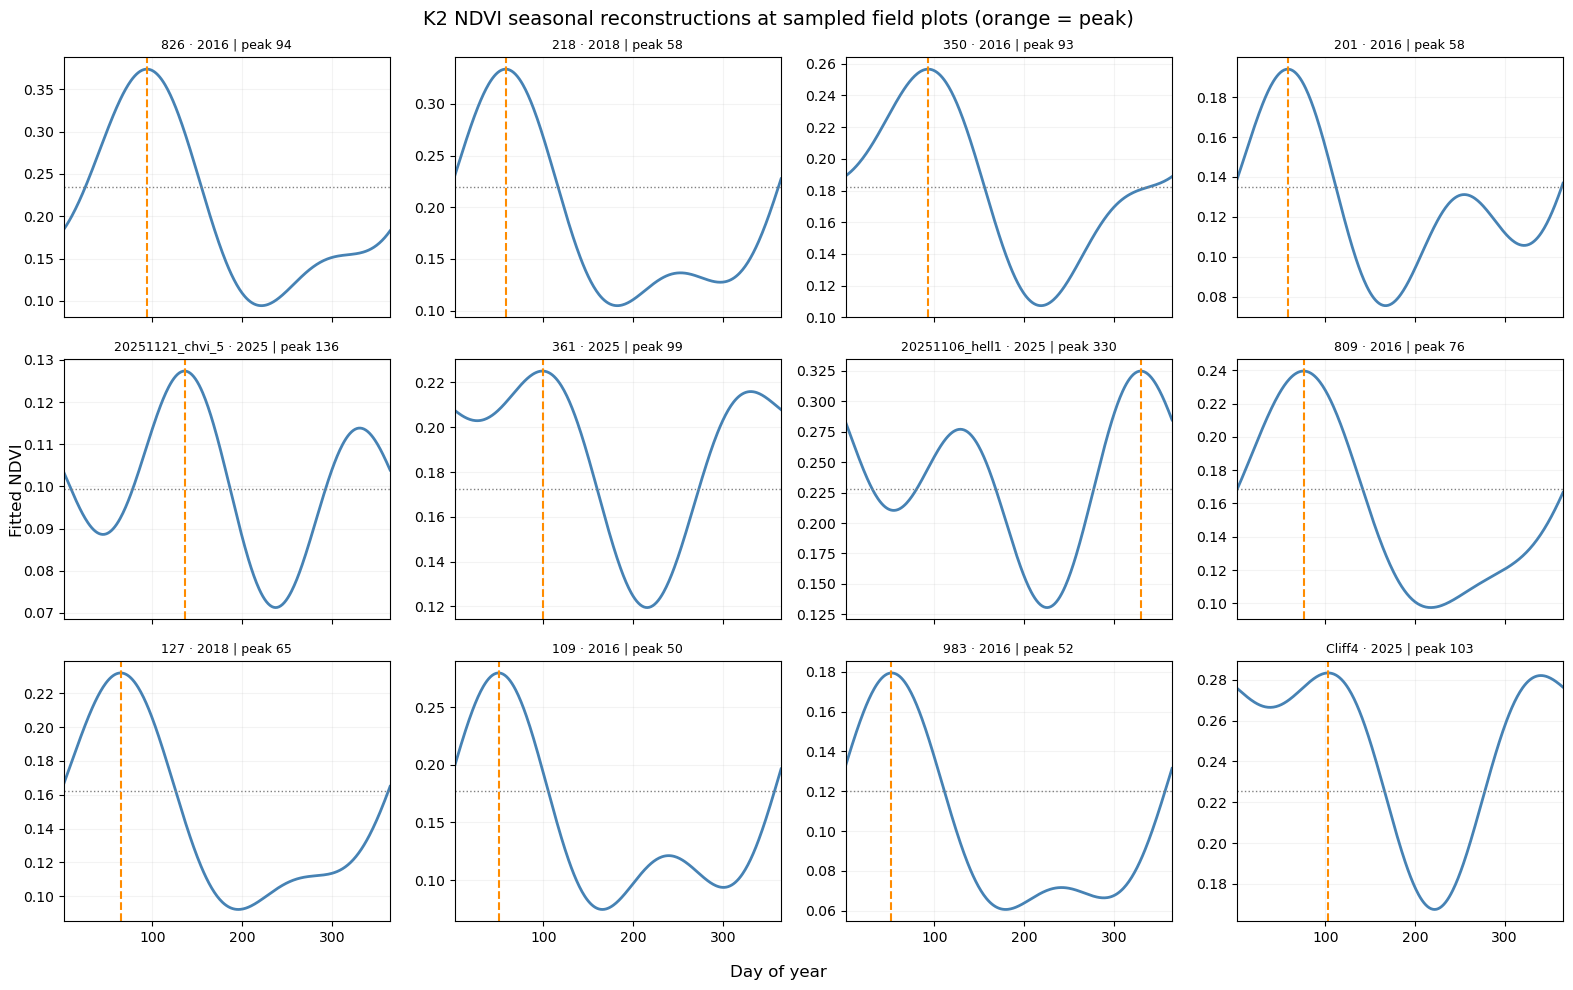

In [10]:
# Representative fitted curves for visual diagnosis, including threshold and peak.
rng=np.random.default_rng(42)
sub=plot_features.sample(n=min(12,len(plot_features)),random_state=42)
fig,axes=plt.subplots(3,4,figsize=(16,10),sharex=True)
for ax,(_,rec) in zip(axes.flat,sub.iterrows()):
    v=reconstruct_ndvi(rec)
    threshold=v.min()+SEASON_THRESHOLD*(v.max()-v.min())
    ax.plot(DOY,v,color='steelblue',lw=2)
    ax.axhline(threshold,color='grey',ls=':',lw=1)
    ax.axvline(rec.peak_ndvi_doy,color='darkorange',lw=1.5,ls='--')
    ax.set_title(f'{rec[PLOT_ID_COL]} · {int(rec[YEAR_COL])} | peak {int(rec.peak_ndvi_doy)}',fontsize=9)
    ax.set_xlim(1,365);ax.grid(alpha=.15)
for ax in axes.flat[len(sub):]:ax.axis('off')
fig.suptitle('K2 NDVI seasonal reconstructions at sampled field plots (orange = peak)',fontsize=14)
fig.supxlabel('Day of year');fig.supylabel('Fitted NDVI');plt.tight_layout();plt.show()


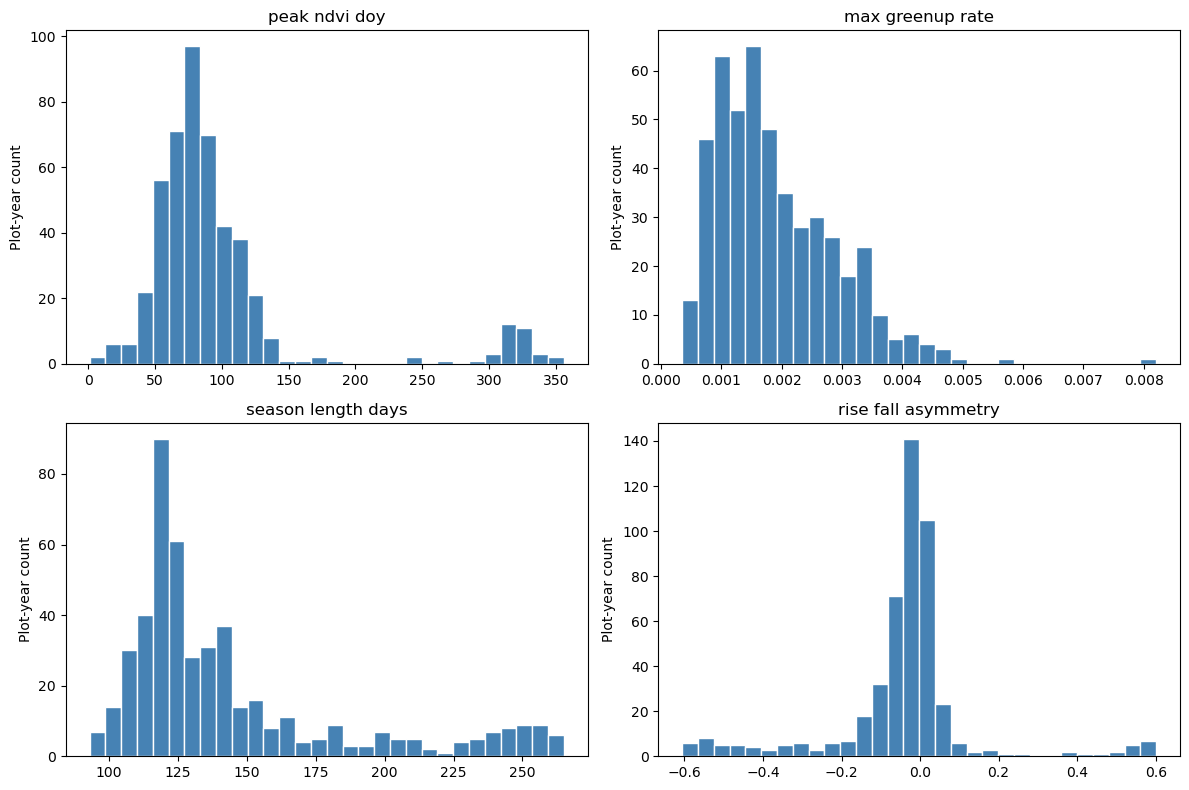

Consecutive plot-year pairs: 0


In [11]:
# Distributions and temporal differences at repeated plot locations.
fields=['peak_ndvi_doy','max_greenup_rate','season_length_days','rise_fall_asymmetry']
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axes.flat,fields):
    x=plot_features.loc[~plot_features.weak_seasonality,col].dropna()
    ax.hist(x,bins=30,edgecolor='white',color='steelblue')
    ax.set_title(col.replace('_',' '));ax.set_ylabel('Plot-year count')
plt.tight_layout();plt.show()

# For circular peak DOY, calculate shortest signed displacement (days).
repeat=plot_features.sort_values([PLOT_ID_COL,YEAR_COL]).copy()
repeat['previous_year']=repeat.groupby(PLOT_ID_COL)[YEAR_COL].shift()
repeat['previous_peak']=repeat.groupby(PLOT_ID_COL)['peak_ndvi_doy'].shift()
repeat=repeat.loc[(repeat[YEAR_COL]-repeat.previous_year)==1].copy()
repeat['peak_shift_days']=((repeat.peak_ndvi_doy-repeat.previous_peak+182.5)%365)-182.5
print('Consecutive plot-year pairs:',len(repeat))
if len(repeat):
    display(repeat[['peak_shift_days']].describe())
    plt.figure(figsize=(8,3));plt.hist(repeat.peak_shift_days,bins=30,color='steelblue')
    plt.title('Interannual change in peak NDVI date at repeated plots')
    plt.xlabel('Signed circular DOY difference (days)');plt.ylabel('Pairs');plt.show()


## Interpretation and safeguards

- **Phase is not validated automatically.** Match `PHASE_CONVENTION`, units, and origin to the export's actual sine/cosine coefficient derivation; compare reconstructed trajectories with observed Sentinel-2 NDVI at known plots before interpreting DOYs.
- Results are **plot-location samples**, not maps. The TIFF may use a different spatial support than the original field-plot training table (buffer averages vs center pixels); don't assume they match.
- Season length uses a **relative 50% amplitude threshold** and the contiguous region surrounding the global peak, with cyclic wrap. It is an operational descriptor, not a validated phenological season.
- Weak and nearly double-peaked fits are flagged but not deleted; inspect their influence before using in classification.
- No GeoTIFF or CSV export is performed. `plot_features` remains in memory for exploration.
- A fitted NDVI peak does **not** necessarily correspond to the observed peak, especially with sparse seasonal coverage or an isolated observation.
